# Dataset Management Demo

**Purpose**: This notebook turns a small corpus into a versioned, tokenized training dataset using the techniques of Chapter 5: shard formats and a document index, manifests and version diffs, packing with document masking, a deterministic and resumable mixture sampler, rank sharding, and dataset statistics, contracts, canaries and a data card. Every section ends in assertions.

**Requirements**: NumPy and Matplotlib only. Everything runs on a CPU in seconds. Files are written to a temporary directory that is removed at the end.

## 1. Setup and a Synthetic Corpus

In [1]:
import gzip
import hashlib
import json
import shutil
import tempfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)
WORK = Path(tempfile.mkdtemp(prefix="llmatlas-ch5-"))

# Three sources with different sizes and length distributions, as a real mixture has.
SOURCES = {"web": (600, 1 / 80), "wiki": (120, 1 / 150), "code": (200, 1 / 120)}
VOCAB = ["the", "of", "and", "to", "in", "a", "model", "data", "token", "shard", "version", "train",
         "sample", "batch", "sequence", "document", "hash", "index", "source", "rank"]


def make_doc(source, i, n_words):
    words = rng.choice(VOCAB, size=n_words)
    return {"id": f"{source}-{i:05d}", "source": source, "text": " ".join(words)}


corpus = []
for source, (n_docs, p) in SOURCES.items():
    for i, n in enumerate(rng.geometric(p, size=n_docs)):
        corpus.append(make_doc(source, i, int(n)))
print(f"{len(corpus)} documents; words per source:",
      {s: sum(len(d['text'].split()) for d in corpus if d['source'] == s) for s in SOURCES})

920 documents; words per source: {'web': 48591, 'wiki': 18211, 'code': 22843}


(nb-dm-formats)=
## 2. Shard Formats and the Document Index

The corpus is written twice: as gzip-compressed JSON Lines shards, which is what gets inspected and versioned, and as a tokenized `uint16` binary with document offsets, which is what training reads. Both carry a manifest with content hashes. Note the bytes-per-token comparison: with a twenty-word vocabulary gzip compresses the text below two bytes per token, so the binary looks larger here; on real text, at four to five bytes per token, the binary is the smaller one, and the point of the binary is zero parsing rather than size.

In [2]:
def write_jsonl_shards(docs, out_dir, docs_per_shard, prefix="shard"):
    out_dir.mkdir(parents=True, exist_ok=True)
    manifest, batch, idx = [], [], 0

    def flush():
        nonlocal batch, idx
        if not batch:
            return
        path = out_dir / f"{prefix}_{idx:05d}.jsonl.gz"
        tmp = path.with_suffix(".tmp")
        raw = b"".join(json.dumps(d, ensure_ascii=False).encode() + b"\n" for d in batch)
        with gzip.open(tmp, "wb", compresslevel=6) as f:
            f.write(raw)
        tmp.rename(path)
        manifest.append({"path": path.name, "records": len(batch), "bytes_uncompressed": len(raw),
                         "bytes_compressed": path.stat().st_size,
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
        batch, idx = [], idx + 1

    for d in docs:
        batch.append(d)
        if len(batch) == docs_per_shard:
            flush()
    flush()
    return manifest


def read_jsonl_shards(out_dir, manifest):
    for m in manifest:
        path = out_dir / m["path"]
        if hashlib.sha256(path.read_bytes()).hexdigest() != m["sha256"]:
            raise IOError(f"{m['path']} does not match its manifest hash")
        with gzip.open(path, "rt", encoding="utf-8") as f:
            for line in f:
                yield json.loads(line)


text_dir = WORK / "v1" / "text"
manifest_v1 = write_jsonl_shards(corpus, text_dir, docs_per_shard=100)
read_back = list(read_jsonl_shards(text_dir, manifest_v1))
print(f"{len(manifest_v1)} shards; compressed/uncompressed bytes:",
      sum(m['bytes_compressed'] for m in manifest_v1), "/", sum(m['bytes_uncompressed'] for m in manifest_v1))
assert [d["id"] for d in read_back] == [d["id"] for d in corpus]
assert not list(text_dir.glob("*.tmp"))

10 shards; compressed/uncompressed bytes: 96064 / 538469


In [3]:
EOD = 0
WORD_TO_ID = {w: i + 1 for i, w in enumerate(VOCAB)}  # a toy tokenizer: one id per word
TOKENIZER_HASH = hashlib.sha256(json.dumps(WORD_TO_ID, sort_keys=True).encode()).hexdigest()[:16]


def tokenize(text):
    return [WORD_TO_ID[w] for w in text.split()]


class TokenShard:
    def __init__(self, path):
        meta = json.loads(path.with_suffix(".json").read_text())
        assert meta["tokenizer_hash"] == TOKENIZER_HASH, "binary built with a different tokenizer"
        self.offsets = np.load(path.with_suffix(".idx.npy"))
        self.tokens = np.memmap(path, dtype=np.dtype(meta["dtype"]), mode="r")

    @classmethod
    def write(cls, path, token_docs, vocab_size):
        dtype = np.uint16 if vocab_size < 2**16 else np.uint32
        offsets, chunks = [0], []
        for toks in token_docs:
            arr = np.asarray(list(toks) + [EOD], dtype=dtype)
            chunks.append(arr)
            offsets.append(offsets[-1] + len(arr))
        np.concatenate(chunks).tofile(path)
        np.save(path.with_suffix(".idx.npy"), np.asarray(offsets, dtype=np.int64))
        path.with_suffix(".json").write_text(json.dumps(
            {"dtype": np.dtype(dtype).name, "tokenizer_hash": TOKENIZER_HASH, "num_docs": len(chunks)}))
        return cls(path)

    def __len__(self):
        return len(self.offsets) - 1

    def document(self, i):
        return np.asarray(self.tokens[self.offsets[i]:self.offsets[i + 1]])


bin_dir = WORK / "v1" / "tokens"
bin_dir.mkdir(parents=True)
shard = TokenShard.write(bin_dir / "all.bin", (tokenize(d["text"]) for d in corpus), vocab_size=len(VOCAB) + 1)
n_tokens = int(shard.offsets[-1])
print(f"{len(shard)} documents, {n_tokens} tokens incl. EOD; bytes per token:")
print(f"  gzip JSONL  {sum(m['bytes_compressed'] for m in manifest_v1) / n_tokens:.2f}")
print(f"  uint16 bin  {(bin_dir / 'all.bin').stat().st_size / n_tokens:.2f}")
assert shard.document(0).tolist() == tokenize(corpus[0]["text"]) + [EOD]
assert shard.document(len(shard) - 1).tolist() == tokenize(corpus[-1]["text"]) + [EOD]
assert shard.tokens.dtype == np.uint16

920 documents, 90565 tokens incl. EOD; bytes per token:
  gzip JSONL  1.06
  uint16 bin  2.00


(nb-dm-versioning)=
## 3. Manifests, Version Roots and Diffs

A version is identified by the hash of its manifest. Rebuilding the corpus with one document changed and one removed changes the root, and the manifest diff names exactly the shards affected. A corrupted shard is caught on read.

In [4]:
def manifest_root(manifest):
    canonical = json.dumps(sorted((m["path"], m["sha256"]) for m in manifest))
    return hashlib.sha256(canonical.encode()).hexdigest()


def diff_manifests(old, new):
    o = {m["path"]: m["sha256"] for m in old}
    n = {m["path"]: m["sha256"] for m in new}
    both = o.keys() & n.keys()
    return {"added": sorted(n.keys() - o.keys()), "removed": sorted(o.keys() - n.keys()),
            "changed": sorted(p for p in both if o[p] != n[p]), "unchanged": sum(o[p] == n[p] for p in both)}


corpus_v2 = [dict(d) for d in corpus if d["id"] != "web-00007"]  # a removal request
corpus_v2[150]["text"] = corpus_v2[150]["text"] + " version"  # a correction
manifest_v2 = write_jsonl_shards(corpus_v2, WORK / "v2" / "text", docs_per_shard=100)
root_v1, root_v2 = manifest_root(manifest_v1), manifest_root(manifest_v2)
print("v1 root", root_v1[:16], "| v2 root", root_v2[:16])
print("diff:", diff_manifests(manifest_v1, manifest_v2))

assert root_v1 != root_v2
assert manifest_root(list(reversed(manifest_v1))) == root_v1
# The removal shifts every document after web-00007 by one, so every shard changes;
# that is the cost of fixed-size shards, and why sources are usually kept in separate shard series.
assert diff_manifests(manifest_v1, manifest_v2)["unchanged"] == 0

# Verification catches a corrupted shard
victim = text_dir / manifest_v1[3]["path"]
original = victim.read_bytes()
victim.write_bytes(original[:-1] + bytes([original[-1] ^ 1]))
try:
    list(read_jsonl_shards(text_dir, manifest_v1))
    raise AssertionError("corruption was not detected")
except IOError as e:
    print("detected:", e)
victim.write_bytes(original)
assert len(list(read_jsonl_shards(text_dir, manifest_v1))) == len(corpus)

v1 root 251f0fd0251db679 | v2 root 51f7a6a41efa154b
diff: {'added': [], 'removed': [], 'changed': ['shard_00000.jsonl.gz', 'shard_00001.jsonl.gz', 'shard_00002.jsonl.gz', 'shard_00003.jsonl.gz', 'shard_00004.jsonl.gz', 'shard_00005.jsonl.gz', 'shard_00006.jsonl.gz', 'shard_00007.jsonl.gz', 'shard_00008.jsonl.gz', 'shard_00009.jsonl.gz'], 'unchanged': 0}
detected: shard_00003.jsonl.gz does not match its manifest hash


(nb-dm-packing)=
## 4. Packing and the Document Mask

The same corpus is packed two ways: concatenate-and-chunk, which splits documents at window boundaries, and best-fit packing, which keeps documents whole at the cost of some padding. The document-causal mask stops tokens attending across documents inside a packed sequence.

chunking: 176 sequences, 18.0% of documents split
packing:  174 sequences, 0.3% padding, 0.7% of documents truncated


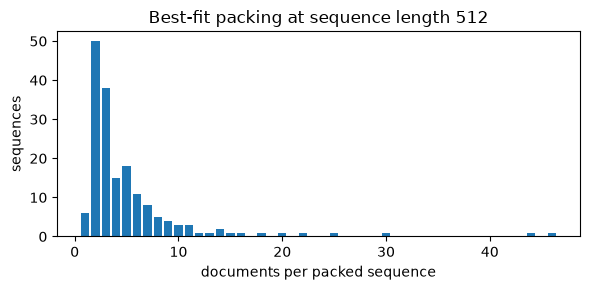

In [5]:
SEQ_LEN = 512
token_docs = [shard.document(i)[:-1].tolist() for i in range(len(shard))]  # without EOD; packers add it


def concat_and_chunk(token_docs, seq_len, eod=0):
    stream, boundaries, pos = [], [], 0
    for doc in token_docs:
        stream.extend(doc)
        stream.append(eod)
        boundaries.append((pos, pos + len(doc)))
        pos += len(doc) + 1
    n_seq = len(stream) // seq_len
    sequences = np.asarray(stream[:n_seq * seq_len]).reshape(n_seq, seq_len)
    split = sum((a // seq_len) != ((b - 1) // seq_len) for a, b in boundaries)
    return sequences, split / len(boundaries)


def best_fit_pack(token_docs, seq_len, eod=0, pad=-1):
    docs = sorted((list(d)[:seq_len - 1] + [eod] for d in token_docs), key=len, reverse=True)
    truncated = sum(len(d) >= seq_len for d in token_docs)
    bins, free, docs_per_bin = [], [], []
    for doc in docs:
        best = None
        for i, space in enumerate(free):
            if len(doc) <= space and (best is None or space < free[best]):
                best = i
        if best is None:
            bins.append(list(doc)); free.append(seq_len - len(doc)); docs_per_bin.append(1)
        else:
            bins[best].extend(doc); free[best] -= len(doc); docs_per_bin[best] += 1
    sequences = np.full((len(bins), seq_len), pad, dtype=np.int64)
    for i, b in enumerate(bins):
        sequences[i, :len(b)] = b
    return sequences, float((sequences == pad).mean()), truncated / len(token_docs), docs_per_bin


chunked, split_frac = concat_and_chunk(token_docs, SEQ_LEN)
packed, pad_frac, trunc_frac, docs_per_bin = best_fit_pack(token_docs, SEQ_LEN)
print(f"chunking: {chunked.shape[0]} sequences, {split_frac:.1%} of documents split")
print(f"packing:  {packed.shape[0]} sequences, {pad_frac:.1%} padding, {trunc_frac:.1%} of documents truncated")
assert split_frac > 0.1
assert trunc_frac < 0.05
assert pad_frac < 0.05
assert abs(packed.shape[0] - chunked.shape[0]) <= 0.1 * chunked.shape[0]

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(docs_per_bin, bins=range(1, max(docs_per_bin) + 2), align="left", rwidth=0.8)
ax.set_xlabel("documents per packed sequence")
ax.set_ylabel("sequences")
ax.set_title(f"Best-fit packing at sequence length {SEQ_LEN}")
plt.tight_layout()
plt.show()

the fullest sequence holds 46 documents; mask has 3199 allowed pairs of 262144


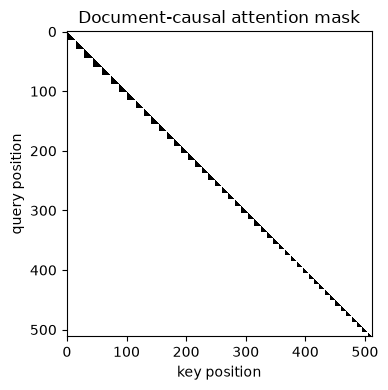

In [6]:
def segment_ids(sequence, eod=0):
    ends = np.asarray(sequence) == eod
    return np.concatenate([[0], np.cumsum(ends)[:-1]])


def document_causal_mask(sequence, eod=0):
    seg = segment_ids(sequence, eod)
    return np.tril(np.ones((len(seg), len(seg)), dtype=bool)) & (seg[:, None] == seg[None, :])


seq = packed[int(np.argmax(docs_per_bin))]  # the sequence holding the most documents
mask = document_causal_mask(seq)
n_docs_in_seq = int(segment_ids(seq).max()) + 1
print(f"the fullest sequence holds {n_docs_in_seq} documents; mask has {mask.sum()} allowed pairs of {mask.size}")
assert mask.sum() < np.tril(np.ones_like(mask)).sum()  # strictly fewer than plain causal
assert all(mask[i, i] for i in range(len(seq)) if seq[i] != -1)

fig, ax = plt.subplots(figsize=(4.2, 4))
ax.imshow(mask, cmap="Greys", interpolation="nearest")
ax.set_title("Document-causal attention mask")
ax.set_xlabel("key position")
ax.set_ylabel("query position")
plt.tight_layout()
plt.show()

(nb-dm-sampler)=
## 5. A Deterministic, Resumable Mixture Sampler

The sampler's state is `(seed, step)`. Temperature flattens the weights ($p_s \propto w_s^{1/T}$), epoch caps re-normalise the mixture once a small source is exhausted, and seeking to any step reproduces the stream exactly.

In [7]:
class MixtureSampler:
    def __init__(self, sizes, weights, seed, temperature=1.0, max_epochs=4.0):
        self.names = sorted(sizes)
        self.sizes = np.array([sizes[n] for n in self.names], dtype=np.int64)
        w = np.array([weights[n] for n in self.names], dtype=np.float64) ** (1.0 / temperature)
        self.probs = w / w.sum()
        self.seed, self.max_epochs = seed, max_epochs
        self.reset()

    def reset(self):
        self.step = 0
        self.cursor = np.zeros(len(self.names), dtype=np.int64)
        self.rng = np.random.default_rng(self.seed)
        self._perm = [None] * len(self.names)

    def _permutation(self, s, epoch):
        if self._perm[s] is None or self._perm[s][0] != epoch:
            self._perm[s] = (epoch, np.random.default_rng([self.seed, s, epoch]).permutation(self.sizes[s]))
        return self._perm[s][1]

    def __next__(self):
        exhausted = self.cursor >= self.sizes * self.max_epochs
        probs = np.where(exhausted, 0.0, self.probs)
        if probs.sum() == 0:
            raise StopIteration
        s = self.rng.choice(len(self.names), p=probs / probs.sum())
        epoch, within = divmod(int(self.cursor[s]), int(self.sizes[s]))
        doc = int(self._permutation(s, epoch)[within])
        self.cursor[s] += 1
        self.step += 1
        return self.names[s], doc

    def __iter__(self):
        return self

    def seek(self, step):
        self.reset()
        for _ in range(step):
            next(self)
        return self


sizes = {s: n for s, (n, _) in SOURCES.items()}
weights = {"web": 0.6, "wiki": 0.25, "code": 0.15}
N_STEPS = 2000

# Resumption at a hundred random steps
reference = [next(x) for x in [MixtureSampler(sizes, weights, seed=7)] for _ in range(N_STEPS)]
for k in rng.integers(0, N_STEPS - 50, size=100):
    resumed = MixtureSampler(sizes, weights, seed=7).seek(int(k))
    assert [next(resumed) for _ in range(50)] == reference[k:k + 50]
print("resumption exact at 100 random steps")

# Within a source, an epoch is a permutation: every document once
wiki_first_epoch = [d for s, d in reference if s == "wiki"][:sizes["wiki"]]
assert sorted(wiki_first_epoch) == list(range(sizes["wiki"]))

resumption exact at 100 random steps


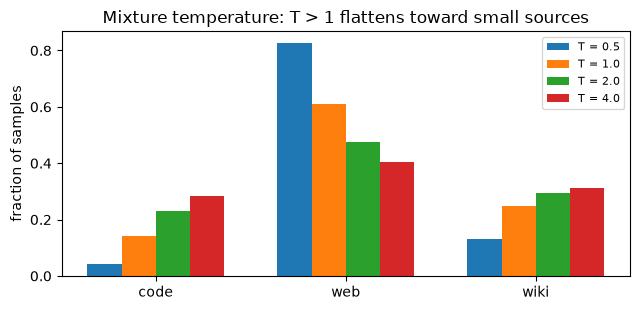

wiki reached 4 epochs at step 1901; sources drawn afterwards: {'web': 867, 'code': 232}


In [8]:
# Realised source fractions vs. target at several temperatures, before any cap binds
temps = [0.5, 1.0, 2.0, 4.0]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
width = 0.18
for j, T in enumerate(temps):
    smp = MixtureSampler(sizes, weights, seed=1, temperature=T, max_epochs=100)
    counts = Counter(s for s, _ in (next(smp) for _ in range(600)))
    frac = [counts[n] / 600 for n in smp.names]
    ax.bar(np.arange(3) + j * width, frac, width, label=f"T = {T}")
    if T == 1.0:
        assert all(abs(frac[i] - smp.probs[i]) < 0.06 for i in range(3)), (frac, smp.probs)
ax.set_xticks(np.arange(3) + 1.5 * width)
ax.set_xticklabels(smp.names)
ax.set_ylabel("fraction of samples")
ax.set_title("Mixture temperature: T > 1 flattens toward small sources")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# The epoch cap: wiki (120 docs, 25%) hits 4 epochs first; after that the mixture is web and code only
smp = MixtureSampler(sizes, weights, seed=3, max_epochs=4.0)
stream = [next(smp) for _ in range(3000)]  # under the 4 * 920 = 3680 total capacity
first_cap = next(i for i in range(len(stream)) if sum(s == "wiki" for s, _ in stream[:i]) == 4 * sizes["wiki"])
after = Counter(s for s, _ in stream[first_cap:])
print(f"wiki reached 4 epochs at step {first_cap}; sources drawn afterwards: {dict(after)}")
assert after["wiki"] == 0 and after["web"] > 0 and after["code"] > 0

(nb-dm-distributed)=
## 6. Sharding Across Ranks

Under shard assignment, each rank owns a disjoint set of shards and the global batch at a step depends on the world size. Under global indexing, every rank runs the same sampler and takes its slice, so the set of samples at a step is identical for any world size.

In [9]:
def rank_shards(num_shards, rank, world_size):
    return list(range(rank, num_shards, world_size))


def global_batch_slice(step, global_batch, rank, world_size):
    per_rank = global_batch // world_size
    start = step * global_batch + rank * per_rank
    return np.arange(start, start + per_rank)


NUM_SHARDS, B, STEP = len(manifest_v1), 64, 11

# Shard assignment: a disjoint cover for every world size, but a different one each time
for W in (1, 2, 4, 8):
    cover = sorted(s for r in range(W) for s in rank_shards(NUM_SHARDS, r, W))
    assert cover == list(range(NUM_SHARDS))
print("rank 0 shards, W=2:", rank_shards(NUM_SHARDS, 0, 2), "| W=4:", rank_shards(NUM_SHARDS, 0, 4))
assert rank_shards(NUM_SHARDS, 0, 2) != rank_shards(NUM_SHARDS, 0, 4)

# Global indexing: the same global batch at STEP for every world size
batches = {}
for W in (1, 2, 4, 8, 16):
    ids = np.concatenate([global_batch_slice(STEP, B, r, W) for r in range(W)])
    assert len(set(ids.tolist())) == B  # no duplicates across ranks
    batches[W] = sorted(ids.tolist())
assert all(batches[W] == batches[1] for W in batches)
print(f"global batch at step {STEP} is samples {batches[1][0]}..{batches[1][-1]} for every world size tested")

rank 0 shards, W=2: [0, 2, 4, 6, 8] | W=4: [0, 4, 8]
global batch at step 11 is samples 704..767 for every world size tested


(nb-dm-governance)=
## 7. Statistics, a Contract, a Canary and a Data Card

The build computes per-source statistics, runs a contract against the plan, checks that a planted canary is where it should be (and nowhere else), and renders a data card from the manifest and statistics.

In [10]:
def dataset_stats(records):
    by_source = {}
    for r in records:
        by_source.setdefault(r["source"], []).append(r["num_tokens"])
    total = sum(sum(v) for v in by_source.values())
    return {s: {"documents": len(v), "tokens": int(sum(v)), "share": sum(v) / total,
                "p50": float(np.percentile(v, 50)), "p99": float(np.percentile(v, 99)), "max": int(max(v))}
            for s, v in by_source.items()}


def check_contract(stats, plan, tolerance=0.05, max_len=100_000):
    failures = []
    for source, target in plan.items():
        if source not in stats:
            failures.append(f"{source}: missing"); continue
        if abs(stats[source]["share"] - target) > tolerance:
            failures.append(f"{source}: share {stats[source]['share']:.3f} vs plan {target:.3f}")
        if stats[source]["max"] > max_len:
            failures.append(f"{source}: document of {stats[source]['max']} tokens exceeds {max_len}")
    failures += [f"{s}: present but not in plan" for s in stats if s not in plan]
    return failures


records = [{"source": d["source"], "num_tokens": len(shard.document(i)) - 1} for i, d in enumerate(corpus)]
stats = dataset_stats(records)
for s, st in stats.items():
    print(f"  {s:<5} docs={st['documents']:>4} tokens={st['tokens']:>6} share={st['share']:.3f} p50={st['p50']:>5.0f} p99={st['p99']:>5.0f} max={st['max']}")

realised_plan = {s: round(stats[s]["share"], 2) for s in stats}
assert check_contract(stats, realised_plan) == []
assert check_contract(stats, {"web": 0.9, "wiki": 0.05, "code": 0.05}) != []
assert any("exceeds" in f for f in check_contract(stats, realised_plan, max_len=100))

  web   docs= 600 tokens= 48591 share=0.542 p50=   56 p99=  346 max=491
  wiki  docs= 120 tokens= 18211 share=0.203 p50=   95 p99= 1017 max=1419
  code  docs= 200 tokens= 22843 share=0.255 p50=   78 p99=  484 max=598


In [11]:
# A canary: a unique string planted in one document of v1, which must be found in v1 and not in v2
CANARY = "canary-" + hashlib.sha256(b"llmatlas-ch5").hexdigest()[:12]
corpus_canary = [dict(d) for d in corpus]
corpus_canary[42]["text"] += " " + CANARY
manifest_c = write_jsonl_shards(corpus_canary, WORK / "v1c" / "text", docs_per_shard=100)
hits_v1c = [d["id"] for d in read_jsonl_shards(WORK / "v1c" / "text", manifest_c) if CANARY in d["text"]]
hits_v2 = [d["id"] for d in read_jsonl_shards(WORK / "v2" / "text", manifest_v2) if CANARY in d["text"]]
print("canary found in:", hits_v1c, "| in v2:", hits_v2)
assert hits_v1c == [corpus[42]["id"]] and hits_v2 == []

# A document index for removal requests: hash -> (version, shard)
locations = {}
for version, man, base in (("v1", manifest_v1, WORK / "v1" / "text"), ("v2", manifest_v2, WORK / "v2" / "text")):
    for m in man:
        with gzip.open(base / m["path"], "rt", encoding="utf-8") as f:
            for line in f:
                d = json.loads(line)
                locations.setdefault(hashlib.sha256(d["text"].encode()).hexdigest(), set()).add((version, m["path"]))
removed = next(d for d in corpus if d["id"] == "web-00007")
where = sorted(locations[hashlib.sha256(removed["text"].encode()).hexdigest()])
print("removed document found in:", where)
assert all(v == "v1" for v, _ in where)

canary found in: ['web-00042'] | in v2: []
removed document found in: [('v1', 'shard_00000.jsonl.gz')]


In [12]:
def data_card(name, version, root, manifest, stats, plan, sources_meta):
    lines = [f"# {name} {version}", "", f"Version root: `{root}`", "",
             f"Shards: {len(manifest)}, records: {sum(m['records'] for m in manifest)}, "
             f"tokens: {sum(s['tokens'] for s in stats.values())}", "",
             "## Composition", "", "| Source | Documents | Tokens | Share | Planned | Licence |",
             "| --- | ---: | ---: | ---: | ---: | --- |"]
    for s, st in sorted(stats.items()):
        lines.append(f"| {s} | {st['documents']} | {st['tokens']} | {st['share']:.3f} | {plan.get(s, 0):.3f} | {sources_meta[s]} |")
    lines += ["", "## Processing", "", "- Tokenizer hash: `" + TOKENIZER_HASH + "`",
              "- Contract: " + ("passed" if not check_contract(stats, plan) else "FAILED"),
              "- Built by: this notebook, seed " + str(SEED), ""]
    return "\n".join(lines)


card = data_card("demo-corpus", "v1", root_v1, manifest_v1, stats, realised_plan,
                 {"web": "CC-BY-4.0 (synthetic)", "wiki": "CC-BY-SA-4.0 (synthetic)", "code": "MIT (synthetic)"})
print(card)
assert "Contract: passed" in card and root_v1 in card

shutil.rmtree(WORK)

# demo-corpus v1

Version root: `251f0fd0251db67992a69a8dfccfc8c69ce1c8588fa14d166eb2f39d62bfa924`

Shards: 10, records: 920, tokens: 89645

## Composition

| Source | Documents | Tokens | Share | Planned | Licence |
| --- | ---: | ---: | ---: | ---: | --- |
| code | 200 | 22843 | 0.255 | 0.250 | MIT (synthetic) |
| web | 600 | 48591 | 0.542 | 0.540 | CC-BY-4.0 (synthetic) |
| wiki | 120 | 18211 | 0.203 | 0.200 | CC-BY-SA-4.0 (synthetic) |

## Processing

- Tokenizer hash: `4052ea8a65370f51`
- Contract: passed
- Built by: this notebook, seed 42



## Summary

- A corpus is written as inspectable text shards and derived tokenized binaries, each with a manifest of content hashes; the tokenized binary is tied to a tokenizer hash.
- A version is the hash of its manifest. Diffs name the shards that changed, and verification catches a corrupted shard. Fixed-size shards over a single document stream mean one removal shifts every shard; per-source shard series localise changes.
- Chunking splits a large fraction of documents at window boundaries; best-fit packing keeps them whole with a few per cent of padding, and the document mask keeps attention within a document.
- A sampler whose state is `(seed, step)` resumes exactly at any step; temperature flattens the mixture and epoch caps re-normalise it once a small source is exhausted.
- Under global indexing, the global batch at a step does not depend on the number of ranks; under shard assignment it does.
- Statistics, a contract, a canary check and a data card are produced by the build, from the same manifest the training run will reference.